# 06 · Payments

**Questions**

1. How often do deposits fail, and does it depend on the payment method or the amount?
2. When a deposit fails, does the player recover, or do we lose the money and the player?
3. How do players use withdrawals?

Reads `stg_deposits`, `stg_withdrawals`, `dim_player`, `fct_player_week`, `fct_player_week_status`. Exports `outputs/payment_methods.csv` and `outputs/deposits_monthly.csv`.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
con = sqlite3.connect(ROOT / "data" / "poker.db")
NAVY, GREY, RED = "#1f4e79", "#8c8c8c", "#b22222"

def q(sql):
    return pd.read_sql_query(sql, con)

## 1. Overview

In [2]:
q("""
select count(*) as deposit_attempts,
       sum(is_completed) as completed,
       round(100.0 * avg(1 - is_completed), 1) as failure_rate_pct,
       round(sum(case when is_completed = 1 then amount end)) as completed_eur,
       round(sum(case when is_completed = 0 then amount end)) as failed_eur,
       round(avg(case when is_completed = 1 then amount end), 1) as avg_completed_eur,
       round(avg(case when is_completed = 0 then amount end), 1) as avg_failed_eur
from stg_deposits
""")

,deposit_attempts,completed,failure_rate_pct,completed_eur,failed_eur,avg_completed_eur,avg_failed_eur
0,293424,222394,24.2,9602520.0,3974615.0,43.2,56.0


About one deposit attempt in four fails. Failed attempts are larger on average than completed ones, which hints that amount matters (section 3).

## 2. Success rate by payment method

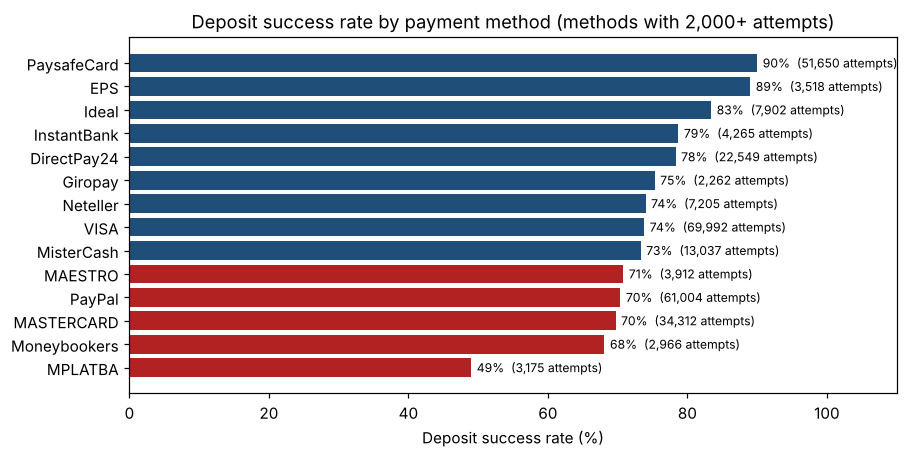

,pay_method,pay_category,attempts,share_of_attempts,success_rate,completed_eur
0,VISA,EEA debit/credit card,69992,0.239,0.738,2215605.0
1,PayPal,eWallet,61004,0.208,0.704,1781025.0
2,PaysafeCard,Voucher,51650,0.176,0.900,1326967.0
3,MASTERCARD,EEA debit/credit card,34312,0.117,0.697,1044849.0
4,DirectPay24,Bank Transfer,22549,0.077,0.783,1172525.0
5,MisterCash,Bank Transfer,13037,0.044,0.733,454077.0
6,Ideal,Bank Transfer,7902,0.027,0.834,289412.0
7,Neteller,eWallet,7205,0.025,0.740,253773.0
8,InstantBank,Bank Transfer,4265,0.015,0.787,141312.0
9,MAESTRO,EEA debit/credit card,3912,0.013,0.708,195153.0


In [3]:
methods = q("""
select pay_method, pay_category, count(*) as attempts,
       round(avg(is_completed), 3) as success_rate,
       round(sum(case when is_completed = 1 then amount else 0 end)) as completed_eur
from stg_deposits group by 1, 2 order by attempts desc
""")
methods["share_of_attempts"] = (methods.attempts / methods.attempts.sum()).round(3)
methods.to_csv(ROOT / "outputs" / "payment_methods.csv", index=False)

top = methods[methods.attempts >= 2000].sort_values("success_rate")
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [RED if r < 0.72 else NAVY for r in top.success_rate]
ax.barh(top.pay_method, top.success_rate * 100, color=colors)
for y, (r, n) in enumerate(zip(top.success_rate, top.attempts)):
    ax.text(r * 100 + 0.8, y, f"{r:.0%}  ({n:,} attempts)", va="center", fontsize=8)
ax.set_xlim(0, 110); ax.set_xlabel("Deposit success rate (%)")
ax.set_title("Deposit success rate by payment method (methods with 2,000+ attempts)")
top.sort_values("attempts", ascending=False)[["pay_method", "pay_category", "attempts", "share_of_attempts", "success_rate", "completed_eur"]]

- **The big card and e-wallet methods are the weak spot.** Visa (74%), PayPal (70%) and Mastercard (70%) together carry 56% of all attempts, and roughly one in four of their attempts fails.
- Prepaid vouchers (PaysafeCard) and local bank methods (EPS in Austria, iDEAL in the Netherlands) succeed 83-90% of the time: the player has already loaded or authorised the money.
- MPLATBA fails about half the time on small amounts and is a candidate for review with the provider.

Card success rates are often limited by issuer declines (some banks block gambling transactions), so the fix is often routing and messaging rather than the card network itself. The data cannot confirm the decline reasons.

## 3. Success rate by amount and over time

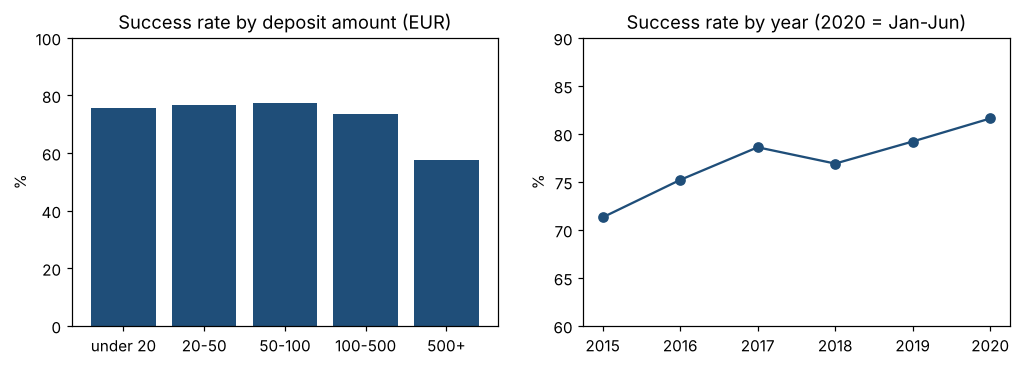

,amount_band_eur,attempts,success_rate
0,1. under 20,124147,0.757
1,2. 20-50,89438,0.766
2,3. 50-100,42249,0.774
3,4. 100-500,34783,0.735
4,5. 500+,2807,0.575


In [4]:
bands = q("""
select case when amount < 20 then '1. under 20'
            when amount < 50 then '2. 20-50'
            when amount < 100 then '3. 50-100'
            when amount < 500 then '4. 100-500'
            else '5. 500+' end as amount_band_eur,
       count(*) as attempts, round(avg(is_completed), 3) as success_rate
from stg_deposits group by 1 order by 1
""")
yearly = q("""
select substr(request_date, 1, 4) as year, count(*) as attempts, round(avg(is_completed), 3) as success_rate
from stg_deposits group by 1 order by 1
""")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(bands.amount_band_eur.str[3:], bands.success_rate * 100, color=NAVY)
axes[0].set_title("Success rate by deposit amount (EUR)"); axes[0].set_ylim(0, 100)
axes[1].plot(yearly.year, yearly.success_rate * 100, marker="o", color=NAVY)
axes[1].set_title("Success rate by year (2020 = Jan-Jun)"); axes[1].set_ylim(60, 90)
for ax in axes: ax.set_ylabel("%")
bands

In [5]:
yearly

,year,attempts,success_rate
0,2015,88323,0.713
1,2016,50576,0.752
2,2017,46419,0.786
3,2018,48414,0.769
4,2019,42656,0.792
5,2020,17036,0.816


- Success is flat up to EUR 500, then drops to 58% for larger deposits, likely card limits and extra checks. High-value players are the ones hitting this.
- The success rate improved every year from 71% in 2015 to over 80% in 2020, so payment operations got better over the period.

## 4. When a deposit fails, what happens next?

Three angles: the same day, the player's very first deposit, and whether the player churns.

In [6]:
same_day = q("""
with d as (
    select player_id, request_date,
           sum(1 - is_completed) as failed, sum(is_completed) as completed,
           sum(case when is_completed = 0 then amount else 0 end) as failed_eur
    from stg_deposits group by 1, 2
)
select count(*) as player_days_with_a_failure,
       round(avg(completed > 0), 3) as recovered_same_day,
       round(sum(case when completed = 0 then failed_eur end)) as failed_eur_not_recovered_same_day
from d where failed > 0
""")
same_day

,player_days_with_a_failure,recovered_same_day,failed_eur_not_recovered_same_day
0,33082,0.659,1109734.0


In [7]:
first = q("""
with fa as (
    select player_id, status, request_date,
           row_number() over (partition by player_id order by request_date, process_time, txn_id) as rn
    from stg_deposits
)
select f.player_id, f.status as first_attempt,
       julianday(d.first_deposit_date) - julianday(f.request_date) as days_to_first_success,
       d.lifetime_net_deposits, d.poker_days
from fa f join dim_player d on d.player_id = f.player_id
where f.rn = 1
""")
failed_first = first[first.first_attempt == "F"]
summary = pd.DataFrame({
    "players": [len(first), len(failed_first)],
    "share": [1.0, len(failed_first) / len(first)],
}, index=["all depositing players", "first attempt failed"])
recovery = pd.Series({
    "same day": (failed_first.days_to_first_success == 0).mean(),
    "within 7 days": (failed_first.days_to_first_success <= 7).mean(),
    "after 30+ days": (failed_first.days_to_first_success > 30).mean(),
    "never": failed_first.days_to_first_success.isna().mean(),
}, name="share of players whose first deposit failed").round(3)
print(summary.round(3).to_string()); print()
recovery.to_frame()

                        players  share
all depositing players     5008  1.000
first attempt failed       1228  0.245



,share of players whose first deposit failed
same day,0.686
within 7 days,0.867
after 30+ days,0.074
never,0.002


In [8]:
first.groupby("first_attempt").agg(players=("player_id", "count"),
                                     median_net_deposits=("lifetime_net_deposits", "median"),
                                     mean_net_deposits=("lifetime_net_deposits", "mean"),
                                     median_poker_days=("poker_days", "median")).round(0)

,players,median_net_deposits,mean_net_deposits,median_poker_days
first_attempt,,,,
F,1228,102.0,1046.0,5.0
S,3780,89.0,1044.0,4.0


In [9]:
churn = q("""
with w as (
    select f.player_id, r.week_num, f.deposits_failed, f.deposits_completed
    from fct_player_week f join ref_week r on r.week_start = f.week_start
    where f.poker_active = 1 and (f.deposits_failed > 0 or f.deposits_completed > 0)
),
ch as (
    select s.player_id, r.week_num as churn_week
    from fct_player_week_status s join ref_week r on r.week_start = s.week_start
    where s.status = 'churned'
)
select case when w.deposits_completed > 0 then 'at least one deposit succeeded'
            else 'all deposits failed' end as active_week_type,
       count(*) as player_weeks,
       round(avg(exists (select 1 from ch where ch.player_id = w.player_id
                         and ch.churn_week between w.week_num + 1 and w.week_num + 5)), 3) as churned_within_5_weeks
from w group by 1
""")
churn

,active_week_type,player_weeks,churned_within_5_weeks
0,all deposits failed,641,0.328
1,at least one deposit succeeded,22940,0.344


**Failed deposits cost money, but in this data they do not cost players.**

- Two thirds of the time, a player whose deposit fails gets one through the same day, usually by retrying or switching method.
- A quarter of players had their very first deposit fail, yet almost all of them deposited successfully later (69% the same day, 87% within a week) and their lifetime value and activity look the same as everyone else's.
- In active weeks where every deposit failed, players were no more likely to churn in the following five weeks.

The cost is **friction and delayed revenue**: about EUR 1.1M of failed attempts were not recovered the same day. Some of that came back later, so it is an upper bound on lost deposits, but it shows where payment improvements pay off: card and PayPal routing, and large deposits.

## 5. Withdrawals: almost half are reversed

In [10]:
wd = q("""
select pay_category, count(*) as requests,
       round(avg(status = 'R'), 3) as reversed_share_of_requests,
       round(avg(amount), 0) as avg_request_eur
from stg_withdrawals group by 1 order by requests desc
""")
tot = q("""
select count(distinct player_id) as players_requesting,
       round(sum(case when status = 'S' then amount end)) as completed_eur,
       round(sum(case when status = 'R' then amount end)) as reversed_eur
from stg_withdrawals
""")
print(tot.to_string(index=False)); print()
wd

 players_requesting  completed_eur  reversed_eur
               1826      4371205.0     5351492.0



,pay_category,requests,reversed_share_of_requests,avg_request_eur
0,Bank Transfer,16591,0.473,350.0
1,eWallet,10918,0.454,229.0
2,EEA debit/credit card,4496,0.478,313.0
3,Voucher,72,0.264,110.0
4,Prepaid Cards,18,0.667,287.0


- About a third of players ever request a withdrawal. Of what they request, **more value is reversed (EUR 5.4M) than actually paid out (EUR 4.4M)**.
- The reversal share is similar across bank transfer, e-wallet and card, so this is player behaviour rather than a payment-method problem: players ask for their money, then change their mind and keep playing.
- For the business this keeps money in play, but it is also a known responsible-gambling marker. A BI team would report it alongside the safer-gambling team rather than treat it purely as upside.

Processing time is not analysed: in this data almost every request is processed the same day it is made.

## 6. Monthly deposit trend for the dashboard

314 rows exported


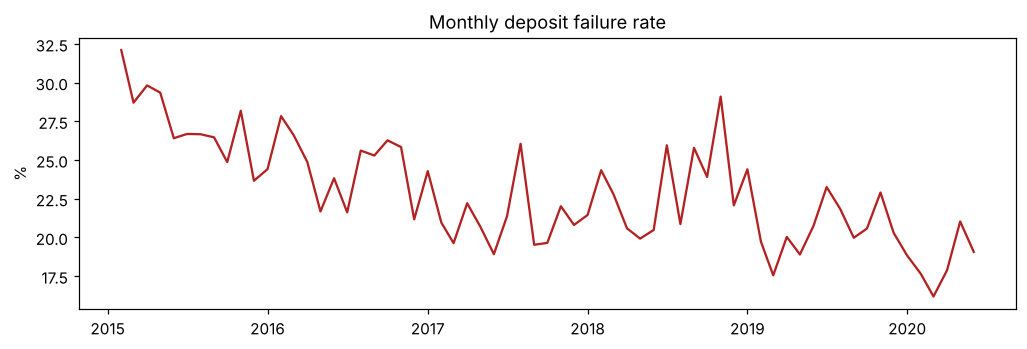

In [11]:
monthly = q("""
select substr(request_date, 1, 7) || '-01' as month, pay_category,
       count(*) as attempts, sum(is_completed) as completed,
       round(sum(case when is_completed = 1 then amount else 0 end), 2) as completed_eur,
       round(sum(case when is_completed = 0 then amount else 0 end), 2) as failed_eur
from stg_deposits group by 1, 2 order by 1, 2
""")
monthly.to_csv(ROOT / "outputs" / "deposits_monthly.csv", index=False)
m = monthly.groupby("month")[["attempts", "completed"]].sum()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pd.to_datetime(m.index), (1 - m.completed / m.attempts) * 100, color=RED)
ax.set_title("Monthly deposit failure rate"); ax.set_ylabel("%")
print(f"{len(monthly):,} rows exported")

## Takeaways

1. **One deposit attempt in four fails**, mostly on cards and PayPal and on deposits above EUR 500. Better routing and clearer decline messages on these methods are the biggest payment lever.
2. **Players are persistent.** Failures delay deposits but did not reduce lifetime value or increase churn in this data, so the cost is friction and timing rather than lost customers.
3. **Withdrawal reversals exceed completed withdrawals** in value. That keeps money in play, and it is also worth monitoring with the safer-gambling team.

In [12]:
con.close()